# Violence Detection Model


## installing requiered libraries and necessary unzipping files

In [1]:
!pip install ultralytics roboflow gdown

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 27.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.0/94.0 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 51.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 46.1 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.13.0.92
    Uninstalling opencv-python-headless-4.13.0.92:
      Successfully uninstalled opencv-python-headless-4.13.0.92
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11


downloading the validation data

In [2]:
from roboflow import Roboflow

import os

# Set ROBOFLOW_API_KEY in your environment before running this cell.
API_KEY = os.getenv("ROBOFLOW_API_KEY")
if not API_KEY:
    raise RuntimeError("Set the ROBOFLOW_API_KEY environment variable first.")
rf = Roboflow(api_key=API_KEY)

project = rf.workspace("east-west-uniersity").project("violance-nonviolance")
dataset = project.version(1).download("yolov8")  # بصيغة YOLOv8

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to violance-nonviolance-1 in yolov8:: 100%|██████████| 5430/5430 [00:02<00:00, 2664.09it/s]


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## loading the model

In [4]:
from ultralytics import YOLO

# Model weights are stored in this repository root.
model = YOLO("yolo_small_weights.pt", task="detect")


## **Visualization and Evaluation**

In [5]:
results = model.val(data="/content/violance-nonviolance-1/data.yaml", conf=0.25)
print("mAP50:", results.box.map50)
print("mAP50‑95:", results.box.map)

Ultralytics 8.4.14 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1065.5±372.3 MB/s, size: 28.1 KB)
val: Scanning /content/violance-nonviolance-1/valid/labels... 543 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 543/543 1.9Kit/s 0.3s
val: New cache created: /content/violance-nonviolance-1/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 3.3it/s 10.3s
                   all        543        830      0.847      0.714      0.807      0.537
          non_violence        148        283      0.721      0.847       0.83      0.523
              violence        508        547      0.972      0.582      0.783       0.55
Speed: 2.4ms preprocess, 8.9ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/runs/detect/val
mAP50: 0.80684052

### Confusion matrix


Correct predictions (diagonal values):

* violence → violence: 347
* non_violence → non_violence: 260

Misclassifications (off-diagonal values):

* violence misclassified as non_violence: 38
* violence misclassified as Background: 162
* non_violence misclassified as violence: 0
* non_violence misclassified as Background: 23
* Background misclassified as non_violence: 220
* Background misclassified as violence: 56

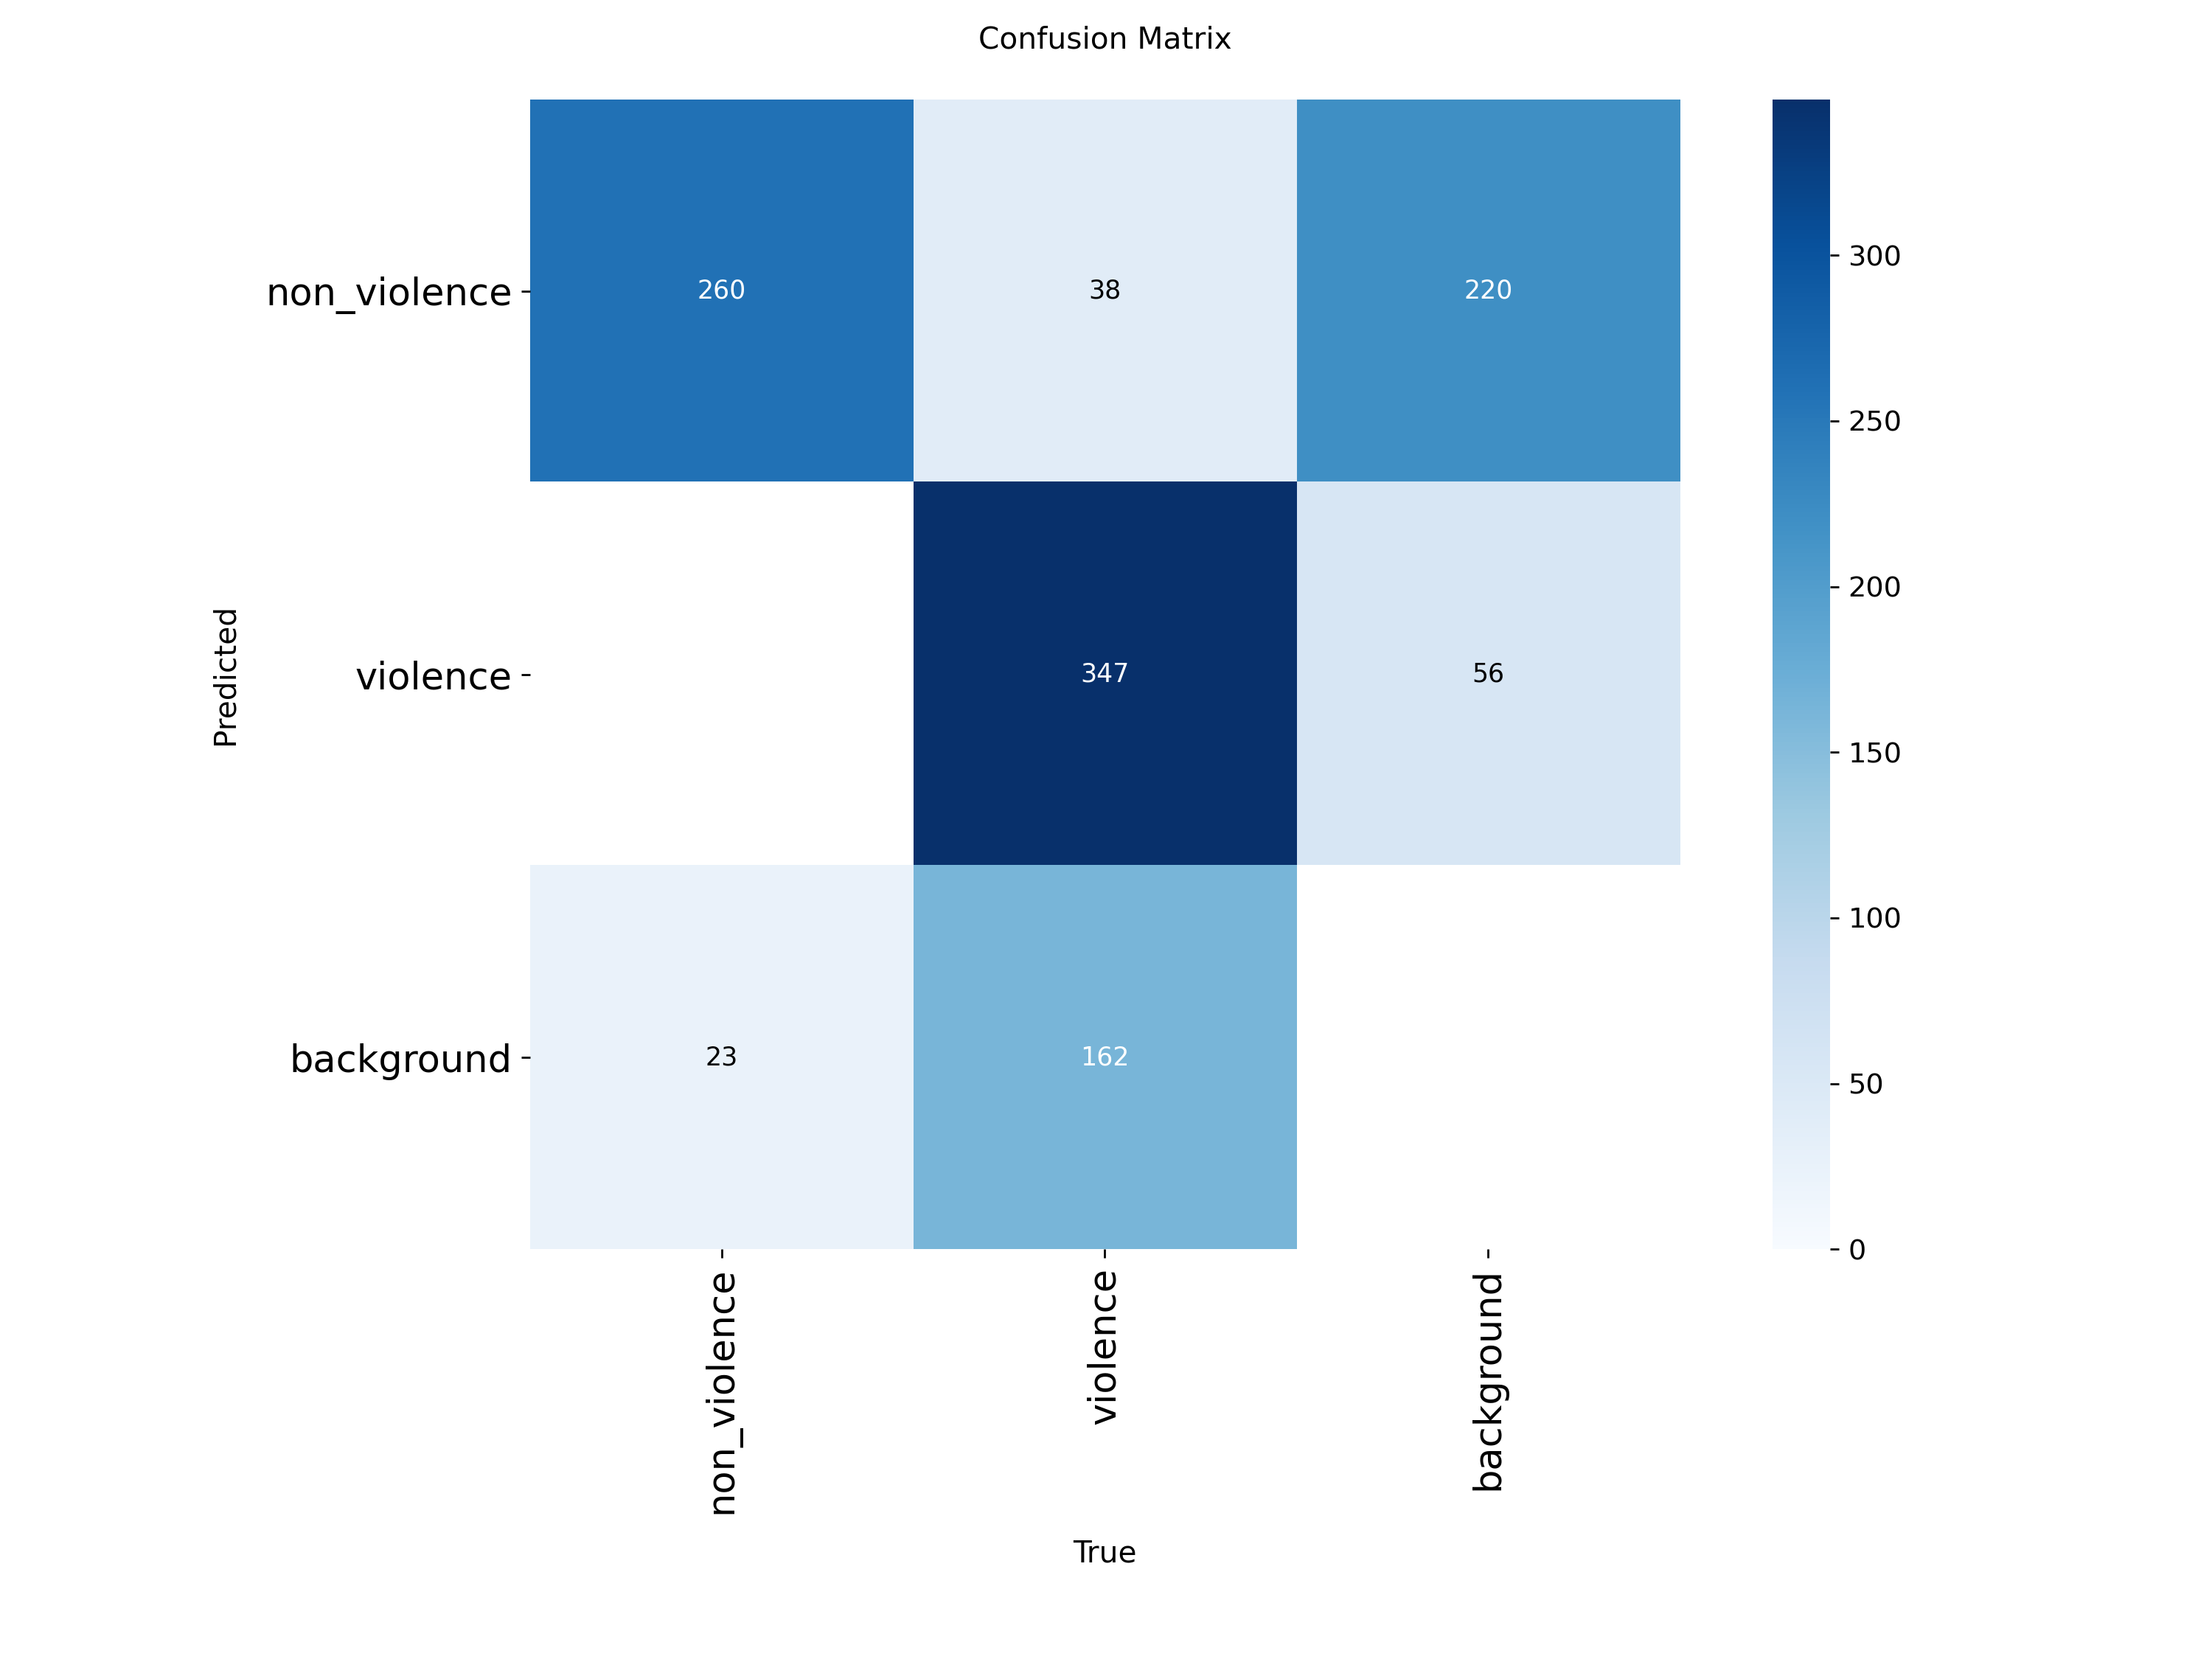

In [8]:
from IPython.display import Image, display
display(Image("/content/runs/detect/val/confusion_matrix.png"))

### Precision-Recall Curve Explanation

This graph shows how well the YOLO model distinguishes between **violent** and **non-violent** classes.

- **X-axis (Recall):** The proportion of actual positives that the model correctly identifies.  
- **Y-axis (Precision):** The proportion of predicted positives that are truly correct.  

#### Curves:
- **Light Blue (non_violence – 0.830):** The model achieves high precision and recall for non-violent cases, meaning it rarely mislabels non-violence as violence.  
- **Orange (violence – 0.783):** Slightly lower performance compared to non-violence, indicating more false positives/negatives when detecting violence.  
- **Dark Blue (all classes – 0.807 mAP@0.5):** The overall mean Average Precision (mAP) at IoU threshold 0.5 across both classes. A score of 0.807 suggests strong overall detection capability.

#### Key Takeaway:
- The model is **better at detecting non-violence** than violence.  
- An overall **mAP@0.5 of 0.807** indicates reliable performance, but improving the violence class detection could further balance the results.


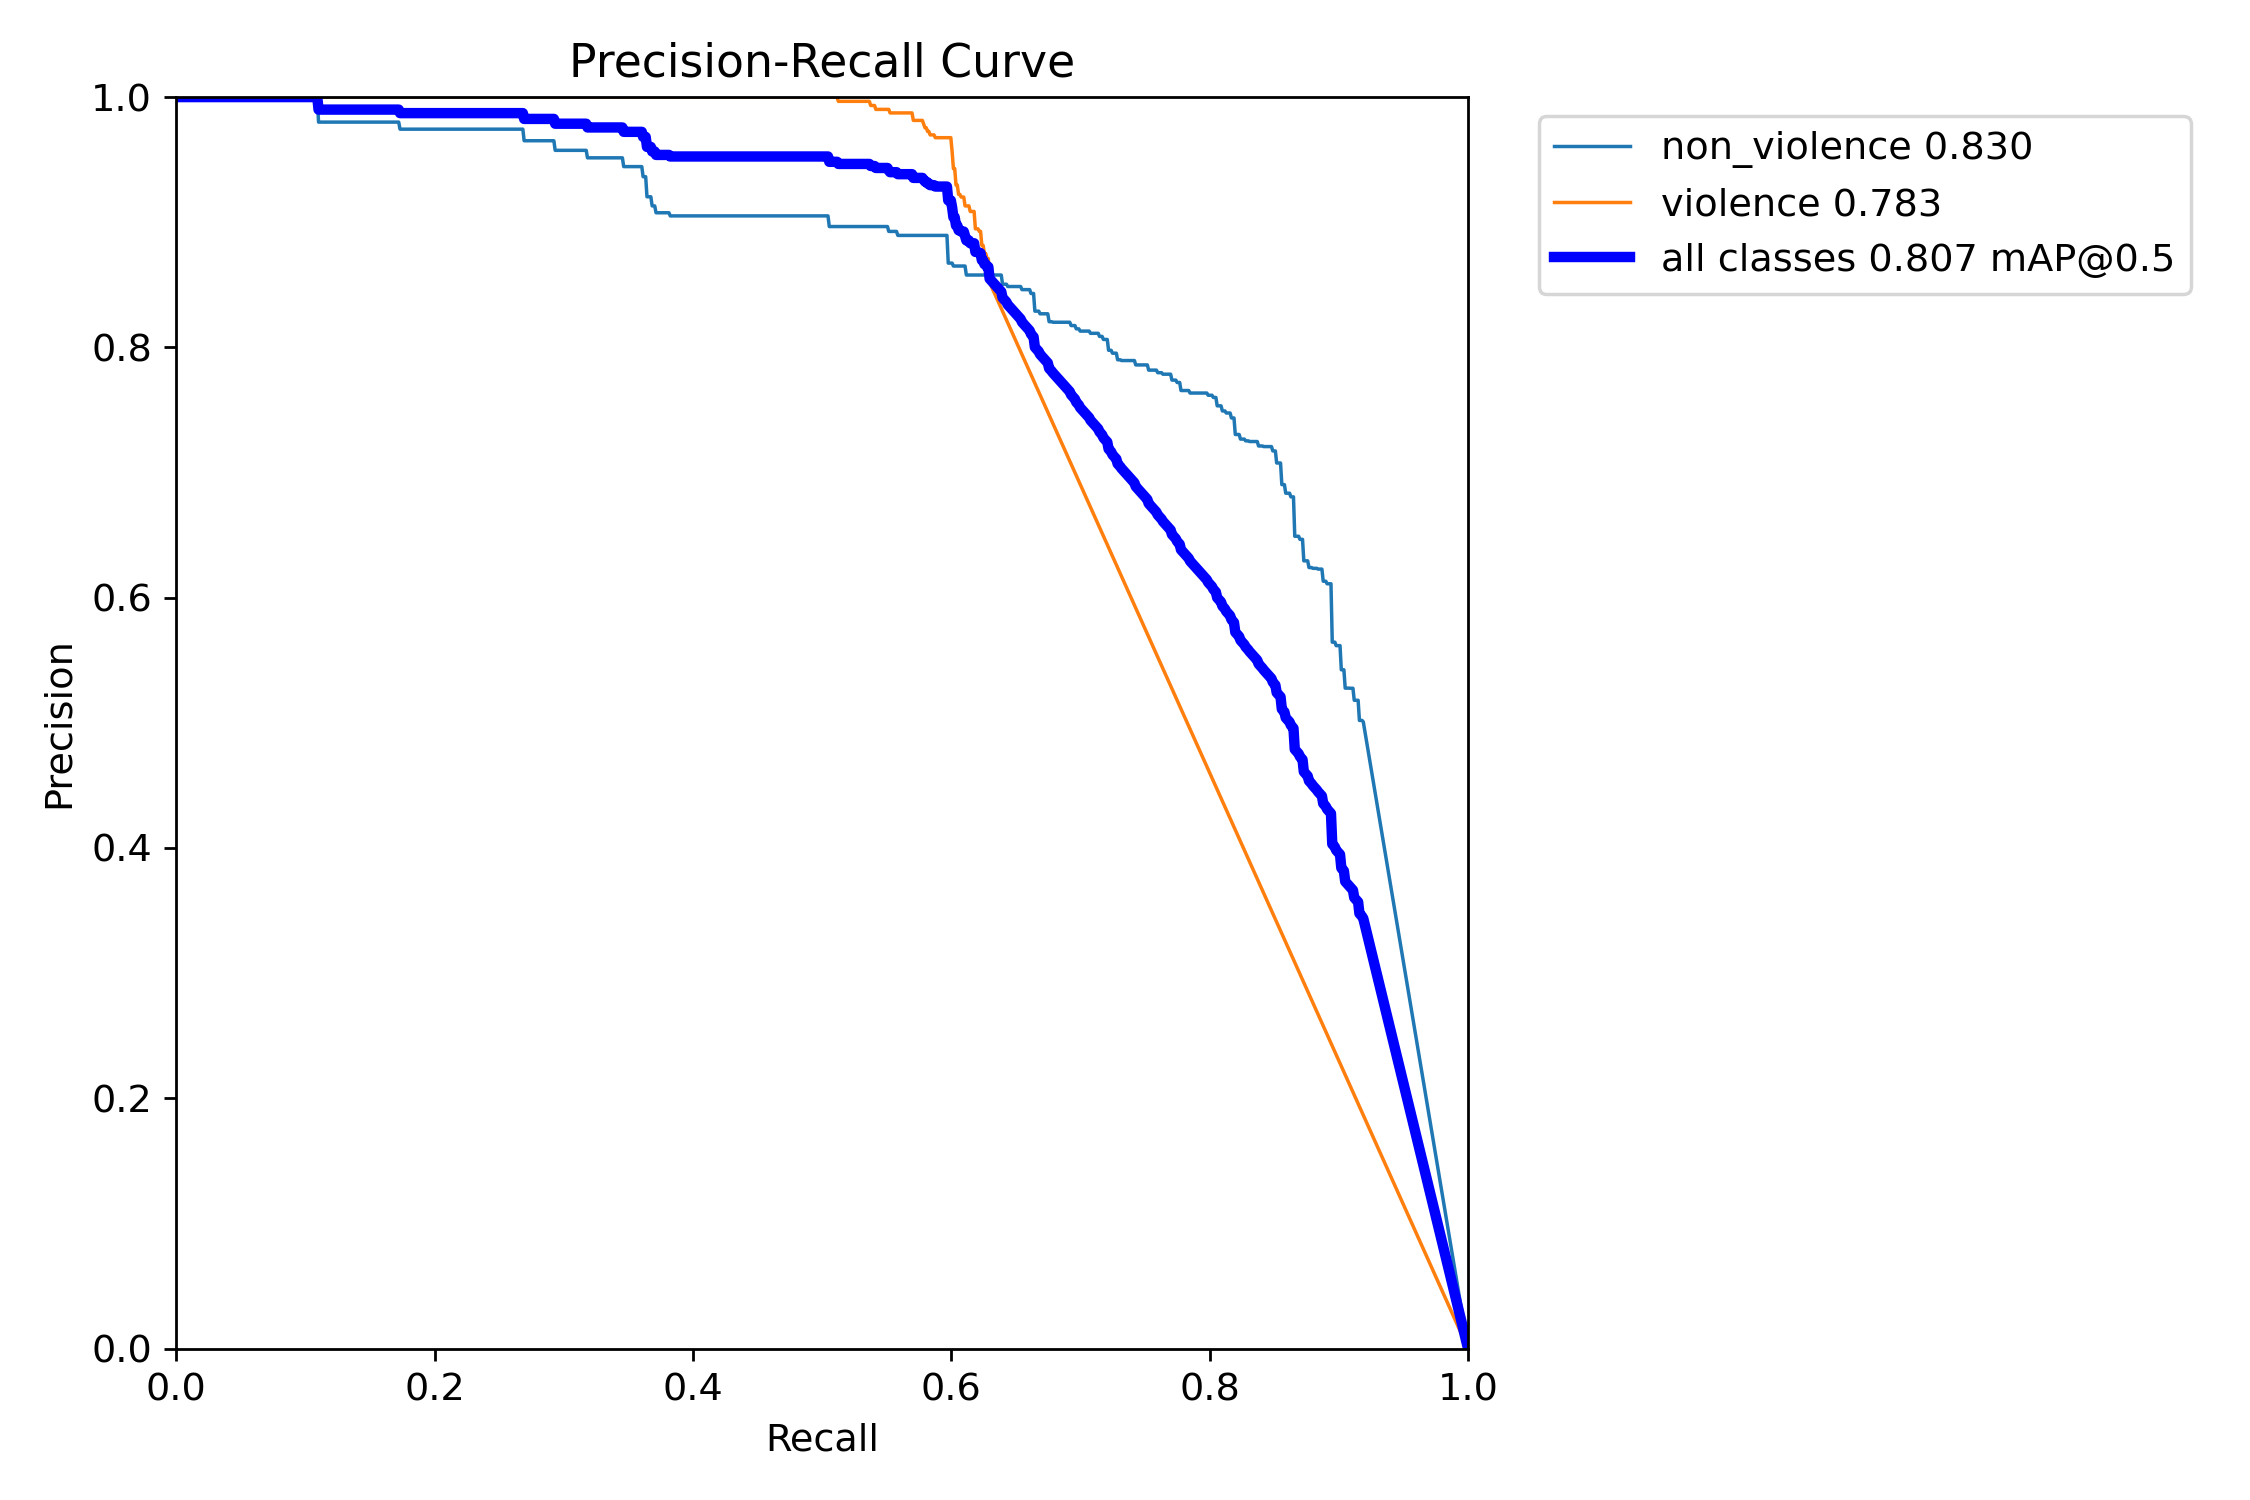

In [9]:
from IPython.display import Image, display
display(Image("/content/runs/detect/val/BoxPR_curve.png"))

### F1–Confidence Curve Explanation

This graph shows how the **F1 score** (balance of precision and recall) changes as we vary the confidence threshold for predictions.

- **X-axis (Confidence):** The minimum confidence required for a prediction to be considered valid.  
- **Y-axis (F1):** The harmonic mean of precision and recall, representing overall classification quality.  

#### Curves:
- **Light Blue (non_violence):** Shows how the F1 score for non-violence changes with confidence.  
- **Orange (violence):** Shows the F1 score for violence across confidence thresholds.  
- **Dark Blue (all classes – 0.75 at 0.582):** Highlights the optimal point where the overall F1 score reaches **0.75** at a confidence threshold of **0.582**.

#### Key Takeaway:
- The model achieves its **best balance of precision and recall** at around **confidence = 0.58**.  
- Setting the threshold near this value can maximize performance across both classes.  
- Non-violence predictions remain slightly stronger than violence, but tuning the threshold helps balance them.


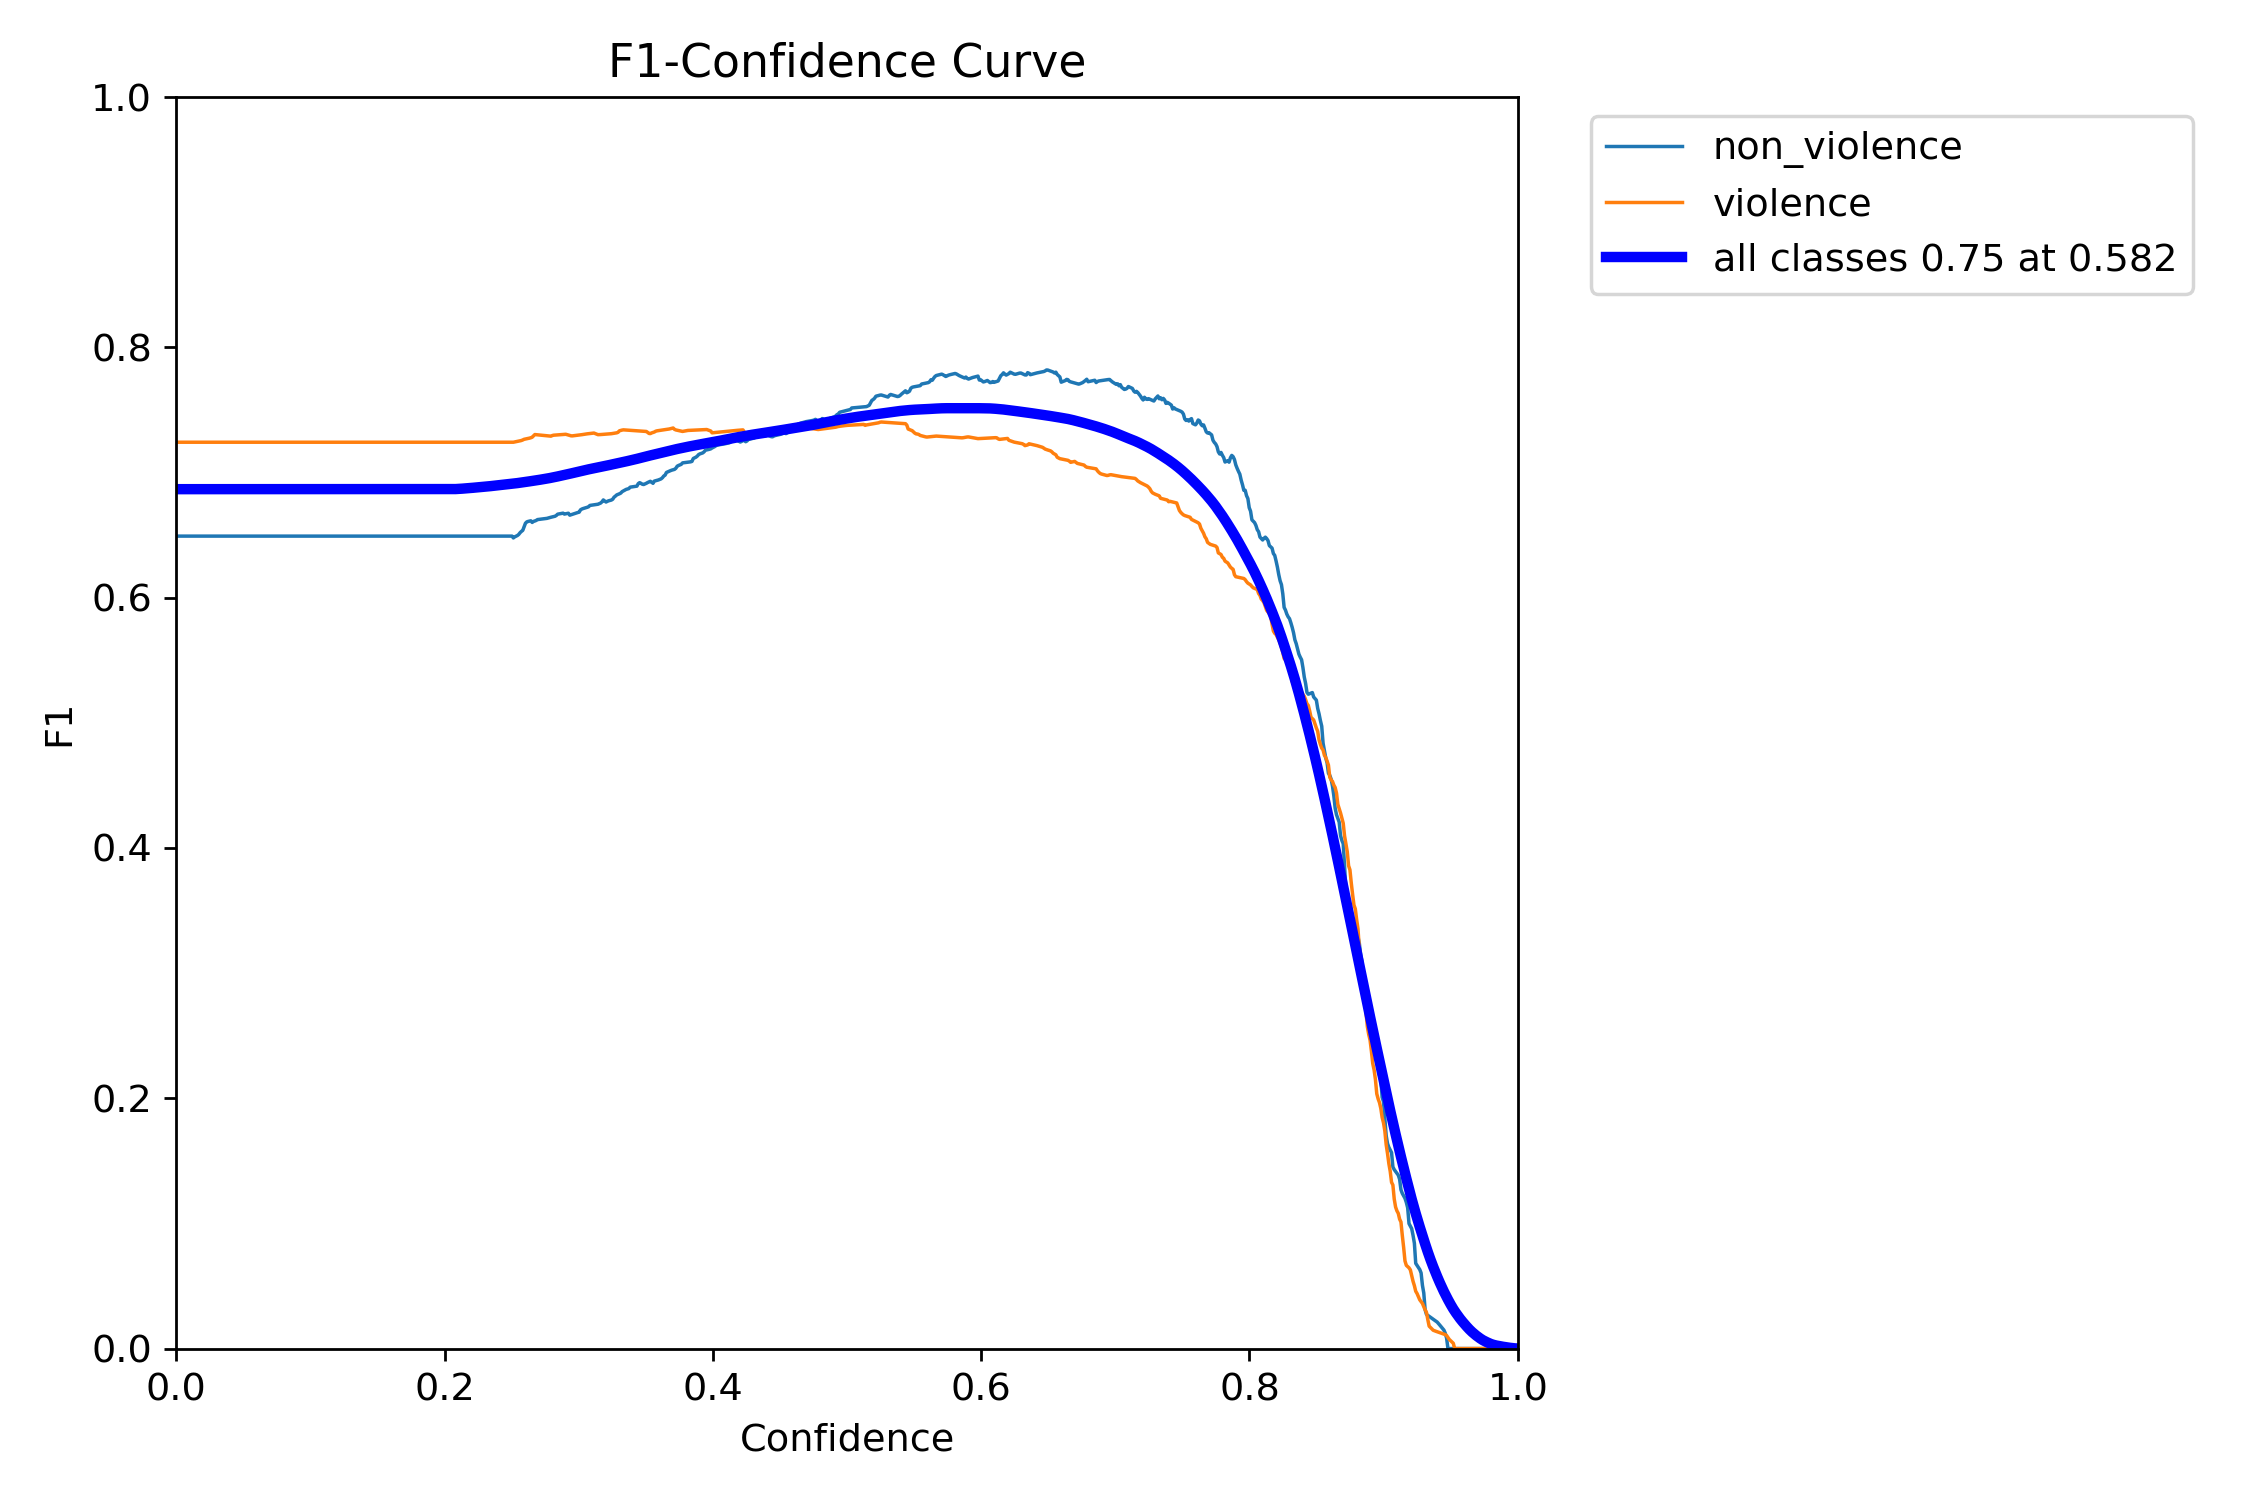

In [10]:
from IPython.display import Image, display
display(Image("/content/runs/detect/val/BoxF1_curve.png"))

### Precision–Confidence Curve Explanation

This graph shows how **precision** changes as we adjust the confidence threshold for predictions.

- **X-axis (Confidence):** The minimum confidence required for a detection to be considered valid.  
- **Y-axis (Precision):** The proportion of predicted positives that are truly correct.  

#### Curves:
- **Light Blue (non_violence):** Precision for the non-violence class across confidence thresholds.  
- **Orange (violence):** Precision for the violence class across confidence thresholds.  
- **Dark Blue (all classes – 1.00 at 0.951):** Highlights the point where overall precision reaches **1.00** at a confidence threshold of **0.951**. This means that at very high confidence, all predictions made are correct, though recall may drop.

#### Key Takeaway:
- Precision increases as confidence rises, since only the most certain predictions are kept.  
- At **confidence ≈ 0.95**, the model achieves perfect precision (no false positives), but this comes at the cost of fewer detections.  
- For practical use, you should balance precision with recall — extremely high confidence thresholds may miss valid detections.


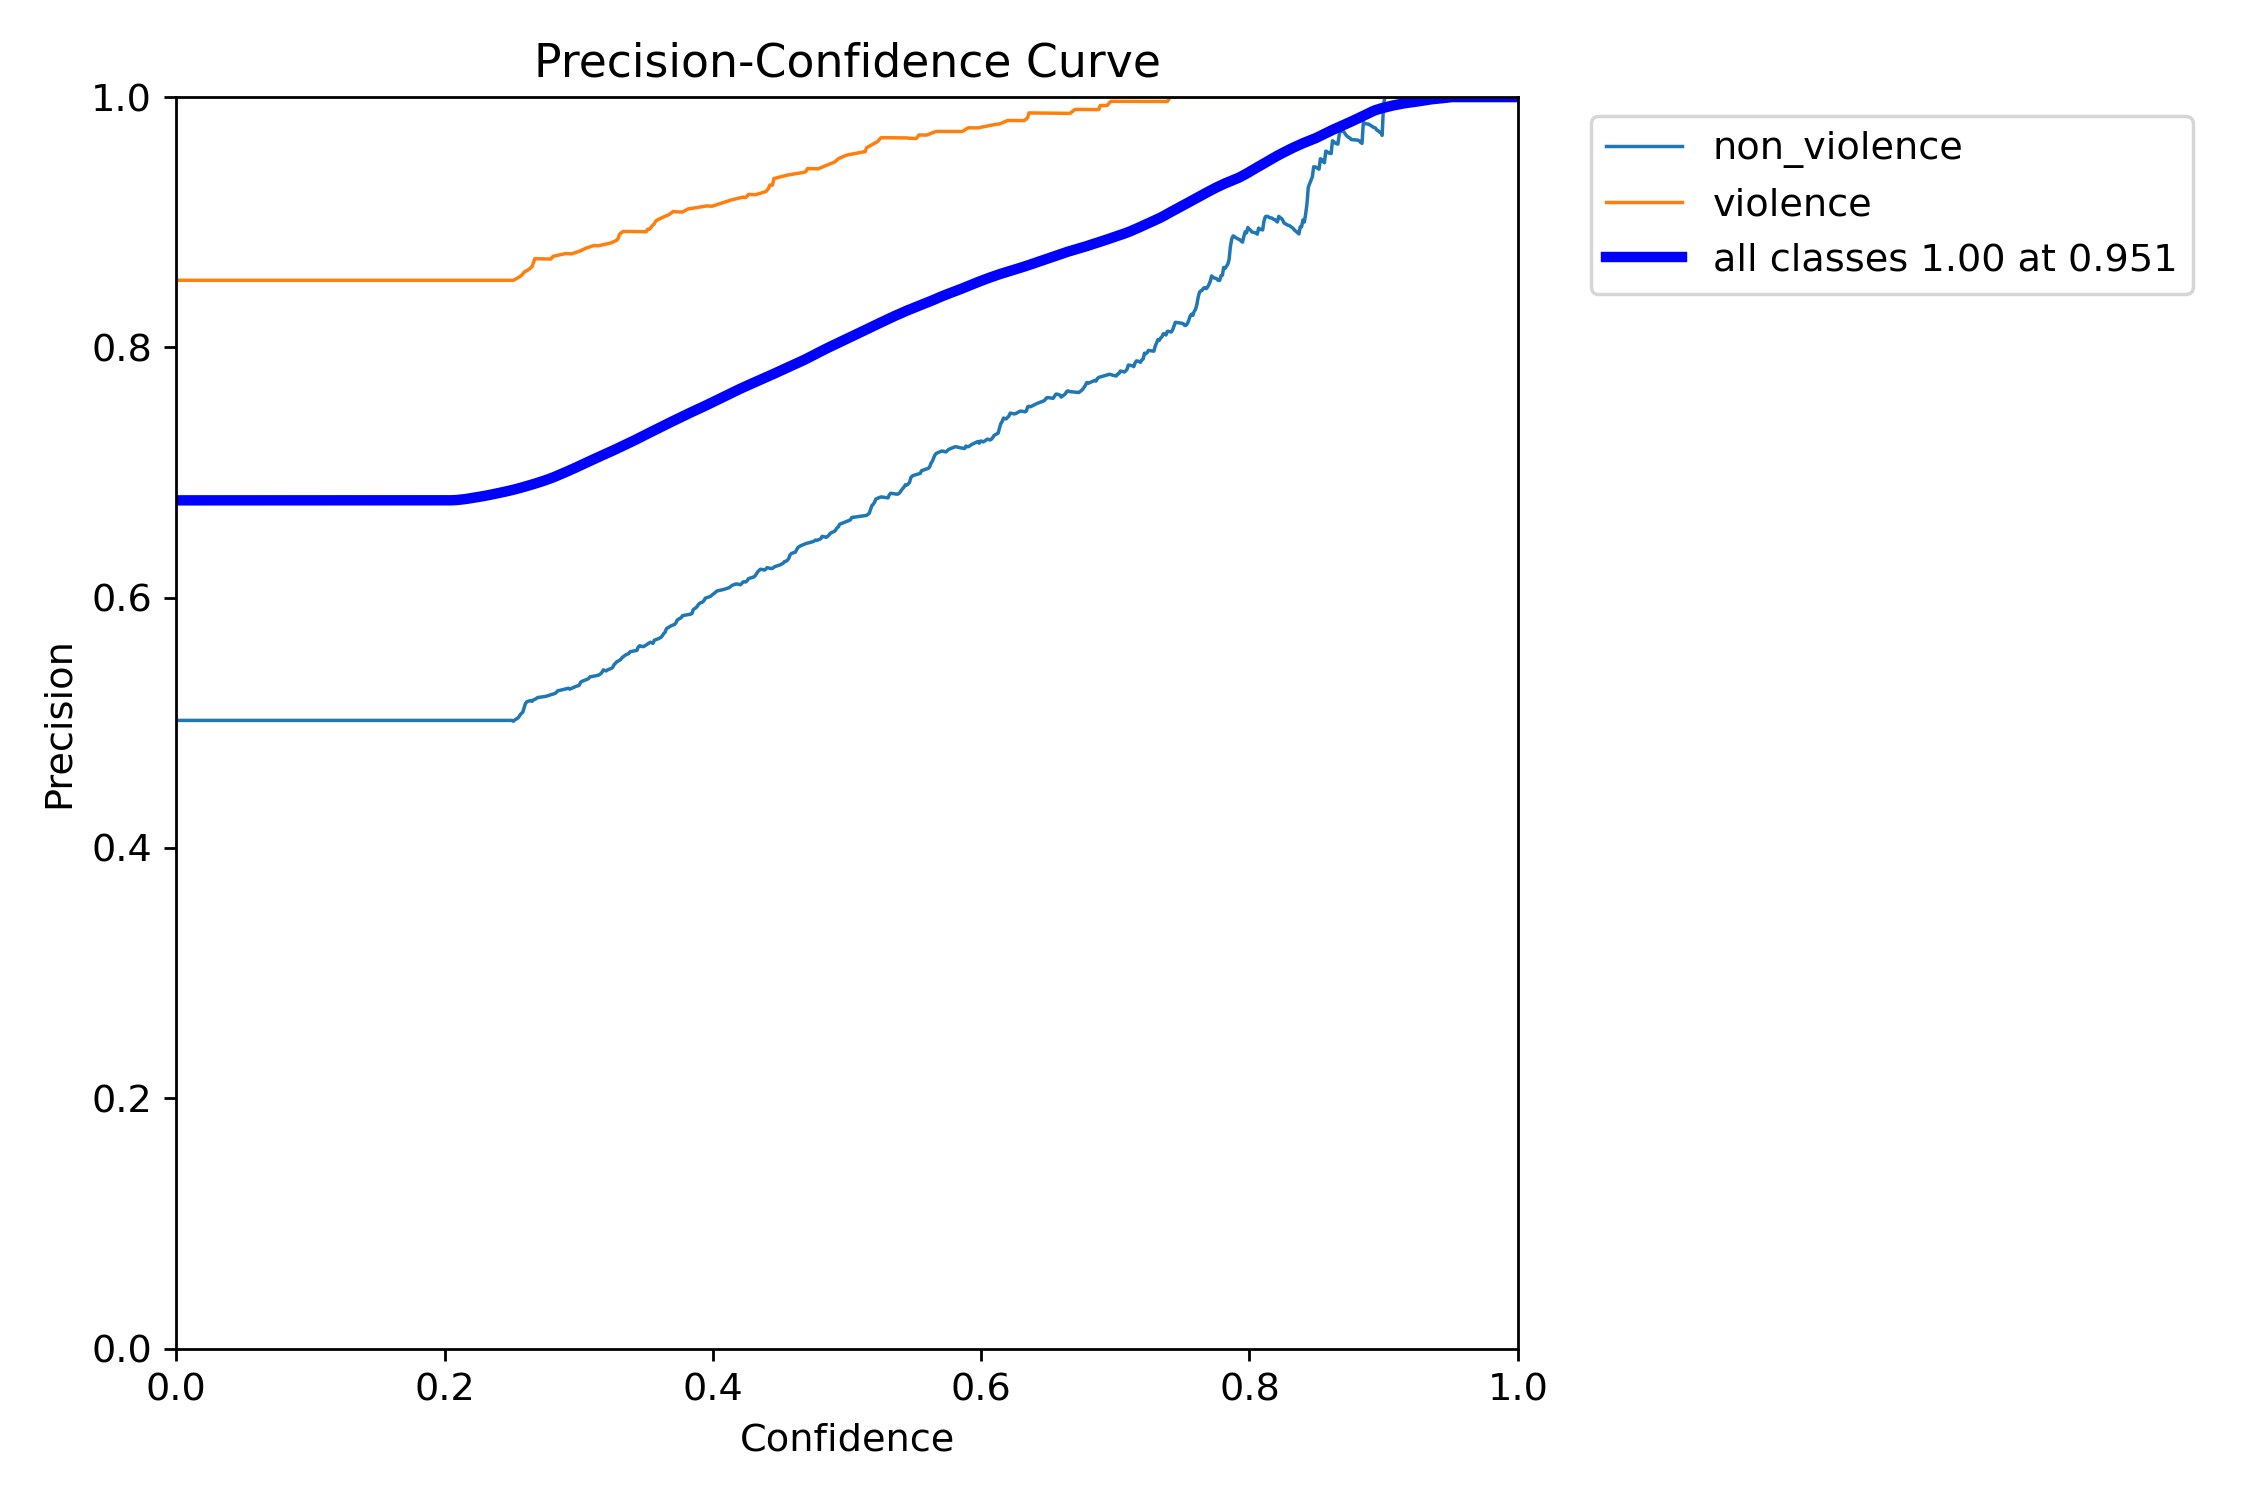

In [11]:
from IPython.display import Image, display
display(Image("/content/runs/detect/val/BoxP_curve.png"))

### Recall–Confidence Curve Explanation

This graph shows how **recall** changes as we adjust the confidence threshold for predictions.

- **X-axis (Confidence):** The minimum confidence required for a detection to be considered valid.  
- **Y-axis (Recall):** The proportion of actual positives that the model correctly identifies.  

#### Curves:
- **Light Blue (non_violence):** Recall for the non-violence class across confidence thresholds.  
- **Orange (violence):** Recall for the violence class across confidence thresholds.  
- **Dark Blue (all classes – 0.77 at 0.000):** Highlights that at **confidence = 0.0**, recall is **0.77** overall. This means the model captures most true positives when all predictions are accepted, but precision may be low.

#### Key Takeaway:
- Recall decreases as confidence increases, since stricter thresholds filter out more predictions (including some correct ones).  
- At very low confidence, recall is high but precision suffers.  
- The optimal threshold should balance recall with precision, depending on whether **missing detections** or **false alarms** are more costly in your application.


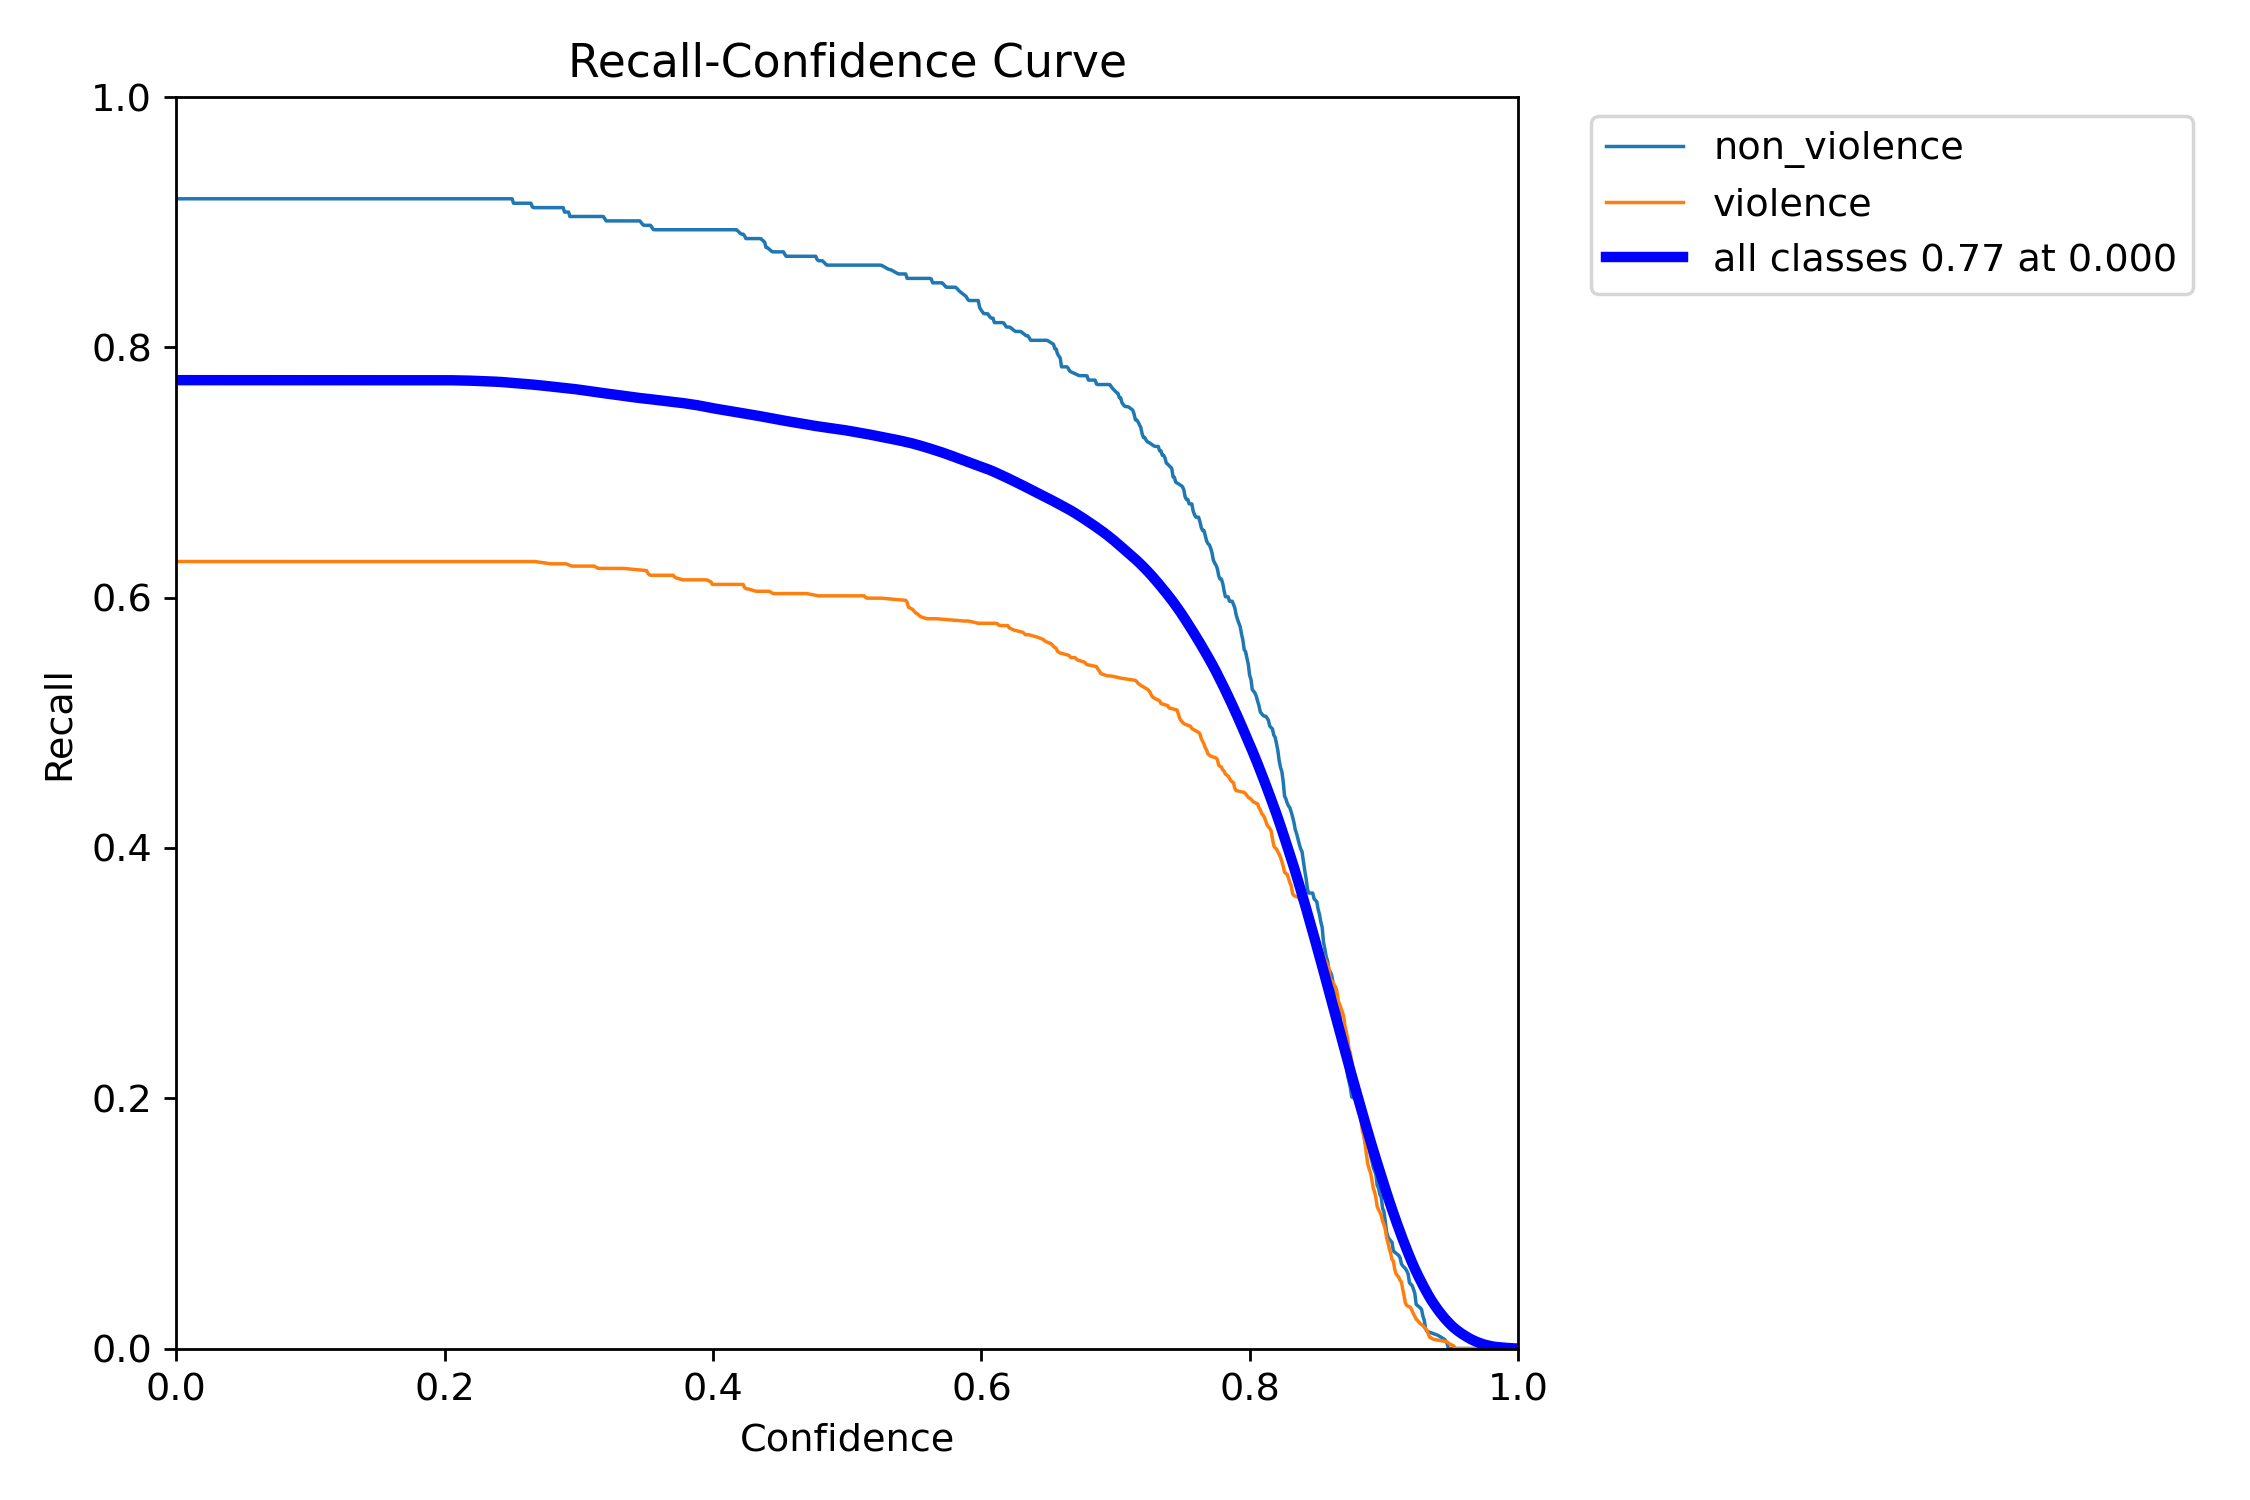

In [12]:
from IPython.display import Image, display
display(Image("/content/runs/detect/val/BoxR_curve.png"))

### YOLO Model Evaluation Results

#### Results:
- **Overall (all classes):**  
  - Precision = **0.847**  
  - Recall = **0.714**  
  - mAP50 = **0.807**  
  - mAP50-95 = **0.537**  

- **Non-violence class:**  
  - Precision = **0.721**  
  - Recall = **0.847**  
  - mAP50 = **0.830**  
  - mAP50-95 = **0.523**  

- **Violence class:**  
  - Precision = **0.972**  
  - Recall = **0.582**  
  - mAP50 = **0.783**  
  - mAP50-95 = **0.550**  

#### Key Takeaways:
- The model is **very precise** at detecting violence (few false positives), but recall is lower (some violent instances are missed).  
- For non-violence, recall is strong (most non-violent cases are detected), but precision is lower (more false positives).  
- Overall performance is solid with **mAP50 ≈ 0.81**, but balancing precision and recall across both classes could improve robustness.  
- Inference speed is efficient (~9ms per image), making the model suitable for real-time applications.


url of the violence detection project:https://huggingface.co/Musawer14/fight_detection_yolov8